                       hour   pm25  temperature   humidity  \
0  2026-06-30T21:00:00.000Z    NaN          NaN        NaN   
1  2026-06-30T22:00:00.000Z    NaN          NaN        NaN   
2  2026-06-30T23:00:00.000Z    NaN          NaN        NaN   
3  2026-07-01T00:00:00.000Z  66.26    21.550000  82.574999   
4  2026-07-01T01:00:00.000Z  63.54    22.033333  87.283333   

                        site  count  meanSpeed  meanDuration   meanTPI  \
0                       None      4   5.558071       2985.75  1.154125   
1                       None      4   5.363622       3075.00  1.188600   
2                       None      4   5.082098       3253.00  1.257350   
3  Kireka, Kira Municipality      4   6.396200       2613.00  1.010000   
4  Kireka, Kira Municipality      4   6.657236       2540.25  0.981950   

   minTPI  minTPIId  maxTPI  maxTPIId  
0  0.8419      4332  1.3610      4334  
1  0.8632      4336  1.3880      4337  
2  0.9032      4341  1.4609      4343  
3  0.7801      4345  1

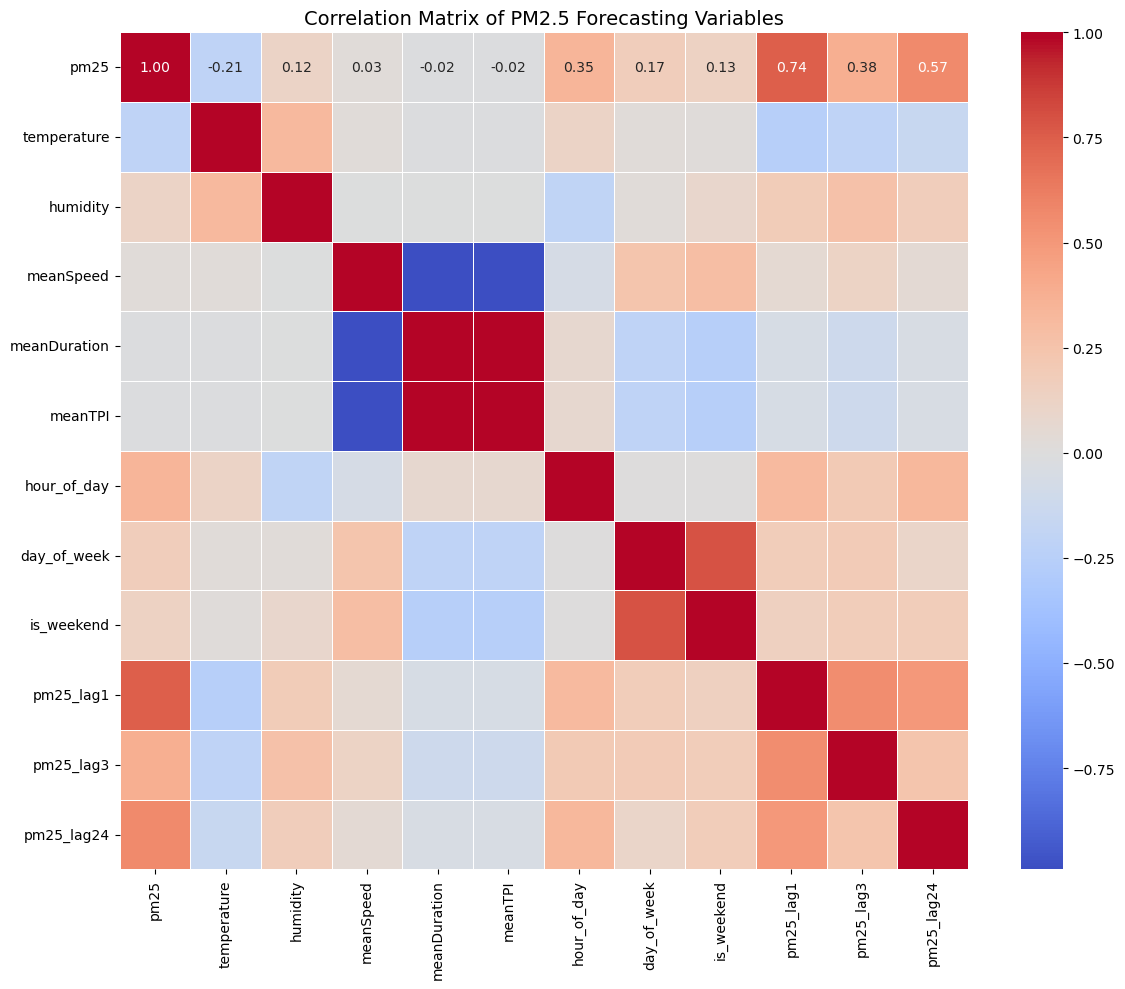


Feature Shape:
(672, 11)

Target Shape:
(672,)

Model Trained Successfully

HGBR + TRAFFIC + LAGGED PM2.5
MAE  : 22.10
RMSE : 31.19
R²   : 0.6245

Feature Importance
         Feature  Importance
2    hour_of_day    0.474403
5      pm25_lag1    0.382039
1       humidity    0.030609
6      pm25_lag3    0.028387
0    temperature    0.024853
9   meanDuration    0.001005
4     is_weekend    0.000000
10       meanTPI   -0.000096
7     pm25_lag24   -0.001491
3    day_of_week   -0.003094
8      meanSpeed   -0.011115


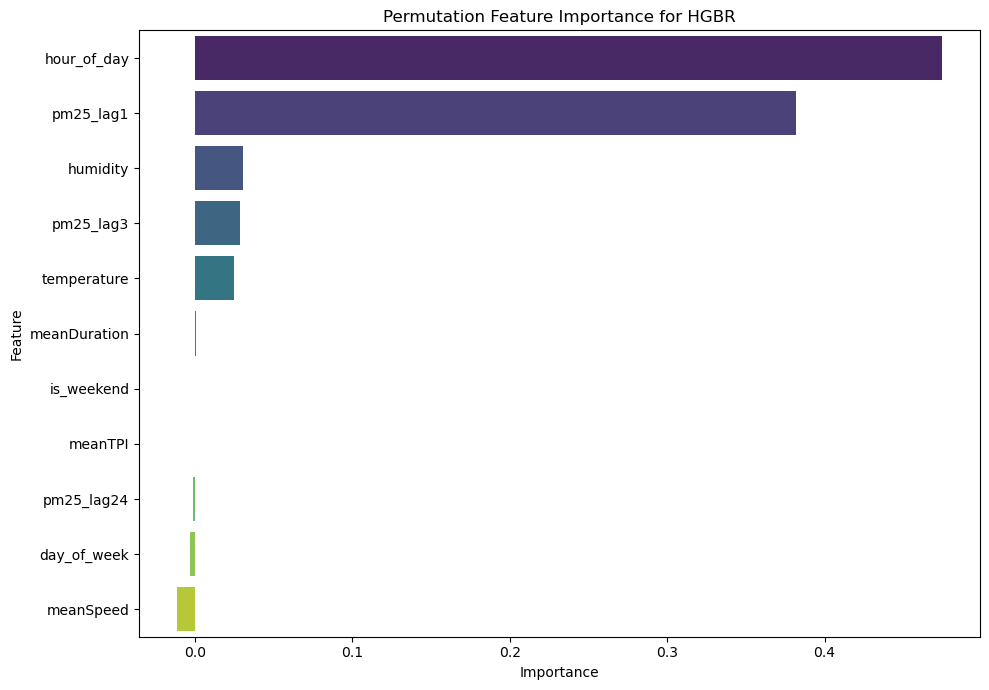

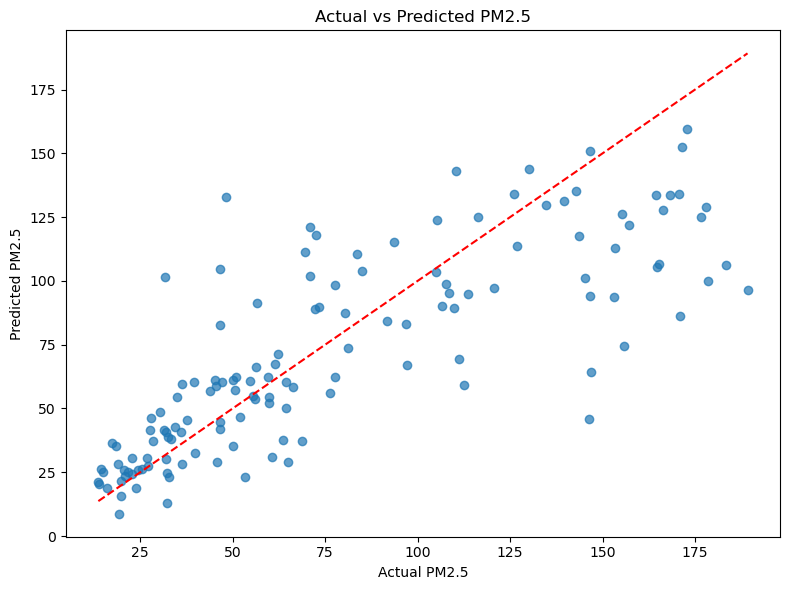

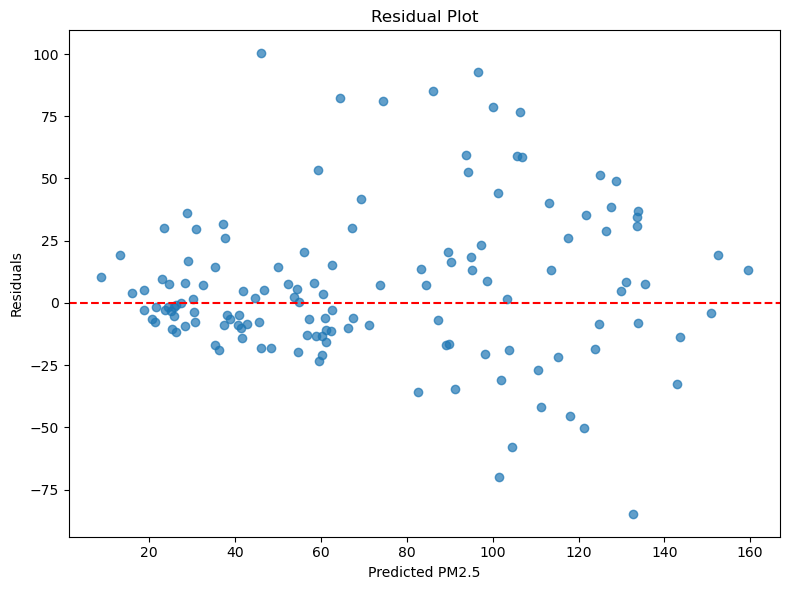

In [1]:

# HistGradientBoostingRegressor (traffic, Lagged PM2.5) model

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#loading my dataset
data = pd.read_json(r"E:\RSXS\Study\project\ParticulateMatterApp\data\ML\merged_record.json")

print(data.head())
print("\nShape:")
print(data.shape)
print("\nColumns:")
print(data.columns)

# creating a working dataset

model_data = data.copy()

# Removing rows with missing critical values
model_data = model_data.dropna(
    subset=[
        "pm25",
        "temperature",
        "humidity",
        "meanSpeed",
        "meanDuration",
        "meanTPI"
    ]
)

print("\nAfter Cleaning:")
print(model_data.shape)

# Datetime Conversion
model_data["hour"] = pd.to_datetime(model_data["hour"])

# Creating Temporal Features
model_data["hour_of_day"] = (model_data["hour"].dt.hour)
model_data["day_of_week"] = (model_data["hour"].dt.dayofweek)
model_data["is_weekend"] = (model_data["day_of_week"] >= 5).astype(int)

#Creating lagged PM2.5 variables
model_data = model_data.sort_values("hour")
model_data["pm25_lag1"] = (model_data["pm25"].shift(1))
model_data["pm25_lag3"] = (model_data["pm25"].shift(3))

model_data["pm25_lag24"] = (model_data["pm25"].shift(24))

# Removing rows created by lagging
model_data = model_data.dropna()
print("\nAfter Lag Creation:")
print(model_data.shape)

# Correlation Analysis
correlation_variables = [
    "pm25",
    "temperature",
    "humidity",
    "meanSpeed",
    "meanDuration",
    "meanTPI",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "pm25_lag1",
    "pm25_lag3",
    "pm25_lag24"
]

corr_matrix = model_data[correlation_variables].corr(method="pearson")
print("\nCorrelation Matrix")
print(corr_matrix)

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of PM2.5 Forecasting Variables",fontsize=14)
plt.tight_layout()
plt.savefig("correlation_heatmap_lagged_model.png", dpi=300, bbox_inches="tight")
plt.show()

# Creating my feature Matrix
X = model_data[
    [
        "temperature",
        "humidity",

        "hour_of_day",
        "day_of_week",
        "is_weekend",

        "pm25_lag1",
        "pm25_lag3",
        "pm25_lag24",

        "meanSpeed",
        "meanDuration",
        "meanTPI"
    ]
]

y = model_data["pm25"]

print("\nFeature Shape:")
print(X.shape)
print("\nTarget Shape:")
print(y.shape)

# Harmonizing the Train Test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = (train_test_split(X,y,test_size=0.20,random_state=42))

from sklearn.ensemble import HistGradientBoostingRegressor
hgb_model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_depth=10, random_state=42)

hgb_model.fit( X_train, y_train)
print("\nModel Trained Successfully")

# Making predictions
y_pred = hgb_model.predict(X_test)

# Evaluation
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
mae = mean_absolute_error(y_test,y_pred)

rmse = np.sqrt(mean_squared_error(y_test,y_pred))
r2 = r2_score(y_test,y_pred)
print("\n===================================")
print("HGBR + TRAFFIC + LAGGED PM2.5")
print("===================================")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

# Permutation Feature Importance
from sklearn.inspection import permutation_importance
results = permutation_importance(hgb_model,X_test,y_test,n_repeats=10,random_state=42)

feature_importance = pd.DataFrame({"Feature": X.columns,"Importance": results.importances_mean})
feature_importance = (feature_importance.sort_values(by="Importance",ascending=False))
print("\nFeature Importance")
print(feature_importance)

plt.figure(figsize=(10,7))

sns.barplot(data=feature_importance,x="Importance",y="Feature",palette="viridis")
plt.title("Permutation Feature Importance for HGBR")
plt.tight_layout()
plt.savefig("hgbr_lagged_feature_importance.png",dpi=300,bbox_inches="tight")
plt.show()

# Looking at the actual vs predicted
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred,alpha=0.7)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],"r--")
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Actual vs Predicted PM2.5")

plt.tight_layout()
plt.show()

# Residual Plot
residuals = (y_test - y_pred)
plt.figure(figsize=(8,6))
plt.scatter(y_pred,residuals,alpha=0.7)
plt.axhline(y=0,color="red",linestyle="--")
plt.xlabel("Predicted PM2.5")
plt.ylabel("Residuals")

plt.title("Residual Plot")
plt.tight_layout()
plt.show()